# 04 · Modelagem

Comparamos **modelos simples (baselines)** com **30 modelos LightGBM** — um por dia à
frente (previsão direta) — no corte de validação de **17/jul/2017**
(1ª quinzena: 17–31/jul · 2ª quinzena: 01–15/ago).

**Métricas**
| Métrica | O que mede | Leitura |
|---|---|---|
| **NWRMSLE** | erro em escala log, perecíveis com peso 1,25 (métrica oficial do Kaggle) | quanto menor, melhor |
| **WAPE diário** | % do volume diário previsto errado | "erramos X% das unidades/dia" |
| **WAPE quinzenal** | % do total da quinzena (por loja × item) previsto errado | visão de **planejamento de compras** |
| **Viés** | previsão total acima (+) ou abaixo (−) do real | + excesso de estoque · − ruptura |

## 1. Setup e carga
Carregamos a base de modelagem gerada no notebook 03 e a lista de feriados nacionais
(usada como feature do dia-alvo).

In [1]:
import sys
sys.path.append("..")

import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.models import national_holidays, baselines, train_direct, to_long
from src.metrics import summarize, nwrmsle, perishable_weights

PROC = Path("../data/processed")
FIG = Path("../reports/figures")
MODELS = Path("../models")
MODELS.mkdir(exist_ok=True)

df_train = pd.read_parquet(PROC / "features_train.parquet")
df_val = pd.read_parquet(PROC / "features_val.parquet")
holidays = national_holidays(pd.read_parquet(PROC / "holidays.parquet"))

print(f"Treino: {df_train.shape} | Validação: {df_val.shape}")
print("Feriados nacionais:", len(holidays))

# Formato padrão das tabelas de resultado
FMT = {"NWRMSLE": "{:.4f}", "WAPE diário": "{:.1%}", "WAPE quinzenal": "{:.1%}", "Viés": "{:+.1%}"}

Treino: (1340120, 100) | Validação: (167515, 100)
Feriados nacionais: 155


## 2. Baselines: a régua mínima
Antes de qualquer Machine Learning, medimos três previsões ingênuas:
- **Média 7 dias:** repete a média da última semana para todos os 30 dias;
- **Média 28 dias:** idem, com as últimas 4 semanas;
- **Média do dia da semana (4 sem.):** para cada dia-alvo, a média do mesmo dia da
  semana nas últimas 4 semanas (captura o padrão semanal).

O LightGBM só se justifica se superar essas referências com folga.

In [2]:
base_preds = baselines(df_val)
long_base = to_long(df_val, base_preds)
summarize(long_base, list(base_preds)).style.format(FMT)

## 3. Teste rápido: um único modelo (h = 1)
Treinamos só o modelo do 1º dia para medir o tempo e estimar a duração total.
O último corte de treino (12/jun) é usado apenas para *early stopping* — o treino
para quando o modelo deixa de melhorar —, mantendo a validação totalmente "às cegas".

In [3]:
start = time.time()
_ = train_direct(df_train, df_val, holidays, horizons=[1])
print(f"\nTempo estimado para os 30 modelos: ~{(time.time() - start) * 30 / 60:.0f} minutos")

h =  1 | árvores:  119 |  10.3 s

Tempo estimado para os 30 modelos: ~5 minutos


## 4. Treino dos 30 modelos (previsão direta)
Um LightGBM por horizonte (h = 1 … 30). Cada modelo recebe as features comuns +
a promoção e o calendário do seu dia-alvo (dia da semana, dia do mês, início de mês,
feriado). Os modelos são salvos em `models/` e as previsões, em `data/processed`.

In [4]:
start = time.time()
lgb_preds, importance = train_direct(df_train, df_val, holidays, models_dir=MODELS)
print(f"\nTempo total: {(time.time() - start) / 60:.1f} min")

# Backup imediato (evita perder o treino se o kernel cair)
np.save(PROC / "lgbm_val_preds.npy", lgb_preds)
importance.rename(columns=str).to_parquet(PROC / "feature_importance.parquet")

h =  1 | árvores:  119 |  10.1 s
h =  2 | árvores:  102 |   9.1 s
h =  3 | árvores:  447 |  21.4 s
h =  4 | árvores:  491 |  26.1 s
h =  5 | árvores:  997 |  48.3 s
h =  6 | árvores:  657 |  34.0 s
h =  7 | árvores:   63 |   8.4 s
h =  8 | árvores:  617 |  33.4 s
h =  9 | árvores:  866 |  42.0 s
h = 10 | árvores:  314 |  25.7 s
h = 11 | árvores:  266 |  20.8 s
h = 12 | árvores:   54 |  10.1 s
h = 13 | árvores:  191 |  19.3 s
h = 14 | árvores:  305 |  31.3 s
h = 15 | árvores:  169 |  20.9 s
h = 16 | árvores:  176 |  21.6 s
h = 17 | árvores:   66 |  16.4 s
h = 18 | árvores:  510 |  48.2 s
h = 19 | árvores:   70 |  14.2 s
h = 20 | árvores:  579 |  45.2 s
h = 21 | árvores:  610 |  51.7 s
h = 22 | árvores:  497 |  41.5 s
h = 23 | árvores:  756 |  56.5 s
h = 24 | árvores:  759 |  58.1 s
h = 25 | árvores:  489 |  40.0 s
h = 26 | árvores: 1000 |  68.3 s
h = 27 | árvores:  987 |  70.8 s
h = 28 | árvores:  999 |  92.2 s
h = 29 | árvores:  998 |  77.9 s
h = 30 | árvores:  888 |  70.9 s

Tempo tot

## 5. Resultado: LightGBM × baselines
Comparamos todos os modelos no período de validação, separando **1ª quinzena**,
**2ª quinzena** e o **total de 30 dias**. Em seguida, calculamos o **ganho do LightGBM**
sobre o melhor baseline de cada período.

In [5]:
# Se o kernel tiver reiniciado, recupera as previsões salvas no backup
lgb_preds = np.load(PROC / "lgbm_val_preds.npy")
base_preds = baselines(df_val)

preds_all = {"LightGBM": lgb_preds, **base_preds}
long = to_long(df_val, preds_all)
resultado = summarize(long, list(preds_all))
resultado.style.format(FMT)

In [6]:
lgbm = resultado.xs("LightGBM", level="Modelo")
melhor_base = resultado.drop(index="LightGBM", level="Modelo").groupby(level="Período").min()

ganho = pd.DataFrame({
    "NWRMSLE: melhoria": (melhor_base["NWRMSLE"] - lgbm["NWRMSLE"]) / melhor_base["NWRMSLE"],
    "WAPE quinzenal: melhoria (p.p.)": (melhor_base["WAPE quinzenal"] - lgbm["WAPE quinzenal"]) * 100,
})
ganho.style.format({"NWRMSLE: melhoria": "{:.1%}", "WAPE quinzenal: melhoria (p.p.)": "{:.1f}"})

,NWRMSLE: melhoria,WAPE quinzenal: melhoria (p.p.)
Período,,
1ª quinzena (d1–15),10.3%,1.1
2ª quinzena (d16–30),7.8%,0.7
30 dias,9.0%,0.9


### 💡 Insights — LightGBM × baselines

**O que os dados mostram**
1. **O LightGBM é o melhor modelo nos dois horizontes**, reduzindo o erro oficial
   (NWRMSLE) em relação ao melhor baseline:
   | Período | LightGBM | Melhor baseline | Melhoria |
   |---|---|---|---|
   | 1ª quinzena | **0,590** | 0,658 (média 28 dias) | **−10,3%** |
   | 2ª quinzena | **0,630** | 0,683 (média 28 dias) | **−7,8%** |
   | 30 dias | **0,610** | 0,671 (média 28 dias) | **−9,0%** |

2. **Prever o total da quinzena é muito mais preciso que prever o dia:** o erro cai de
   **~52% (diário)** para **~30% (quinzenal)**, porque os erros diários para cima e
   para baixo se compensam. É a visão que interessa ao **planejamento de compras**.
3. **No volume em unidades, a vantagem é menor** (WAPE quinzenal 29,9% contra 31,0% do
   melhor baseline): a métrica oficial, em escala log, valoriza acertar itens de baixo
   giro, enquanto o WAPE é dominado pelos itens de alto volume.
4. **⚠️ Viés negativo em todos os modelos (≈ −20%)**: as previsões somam ~20% **menos**
   unidades do que o realizado. A causa é técnica: ao treinar em `log(1 + vendas)`, o
   modelo aprende a "média dos logs", que é sempre **menor** que a média das vendas
   (desigualdade de Jensen) — e a diferença cresce em itens com vendas irregulares.

**Implicação gerencial**
Usada sem ajuste, a previsão levaria a **compras ~20% abaixo da demanda → ruptura**.
O modelo que otimiza a métrica oficial **não é, sozinho, o ideal para o negócio**: é
preciso **calibrar** a previsão para o volume em unidades (próximo notebook).

## 6. Erro por dia à frente (h = 1 … 30)
Como o erro de cada modelo evolui ao longo do horizonte? Esperamos que o erro cresça
com a distância — e que o LightGBM mantenha a vantagem nas duas quinzenas.

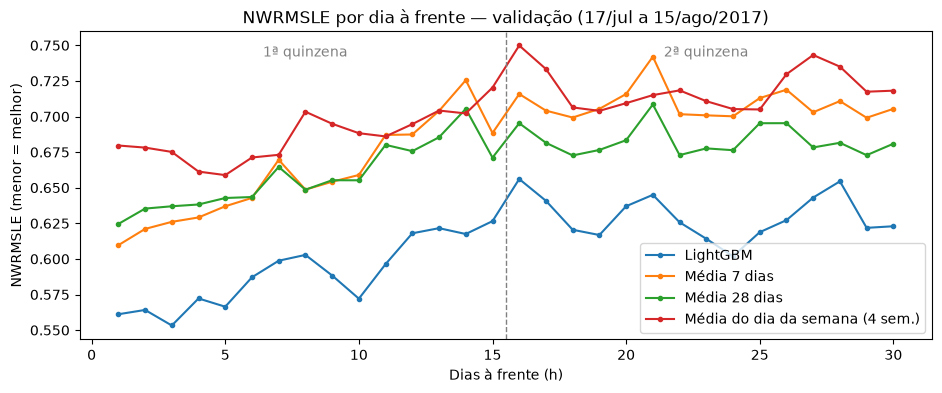

In [7]:
por_h = long.groupby("h").apply(
    lambda g: pd.Series({m: nwrmsle(g["y_true"], g[m], perishable_weights(g["perishable"]))
                         for m in preds_all})
)

ax = por_h.plot(figsize=(11, 4), marker="o", ms=3)
ax.axvline(15.5, color="gray", ls="--", lw=1)
ax.text(8, por_h.values.max(), "1ª quinzena", ha="center", va="top", color="gray")
ax.text(23, por_h.values.max(), "2ª quinzena", ha="center", va="top", color="gray")
ax.set(title="NWRMSLE por dia à frente — validação (17/jul a 15/ago/2017)",
       xlabel="Dias à frente (h)", ylabel="NWRMSLE (menor = melhor)")
plt.savefig(FIG / "04_erro_por_horizonte.png", dpi=120, bbox_inches="tight")
plt.show()

### 💡 Insights — Erro por dia à frente

1. **A vantagem do LightGBM é consistente:** ele fica abaixo de todos os baselines
   em **todos os 30 dias**, com uma distância de ~0,05 a 0,10 no NWRMSLE.
2. **O erro cresce com o horizonte**, de ~0,56 nos primeiros dias para ~0,62–0,65
   na 2ª quinzena — a 2ª quinzena é ~7% mais difícil.
3. **Os picos de erro coincidem com eventos de calendário:**
   - **h = 16 (01/ago):** início de mês, o pico de demanda pós-pagamento (EDA, seção 5);
   - **h = 26–28 (11 a 13/ago):** feriado da Independência transferido para sexta-feira,
     criando um **fim de semana prolongado**.

   Esses eventos são justamente os mais difíceis de prever — e onde há espaço para
   melhorar as *features* de calendário.
4. Os baselines de média simples **pioram mais rápido** na 2ª quinzena (a média de
   7 dias passa de 0,61 para ~0,71), enquanto o LightGBM é mais estável.

## 7. Importância das features
Somamos o **ganho** (*gain*) de cada feature nos 30 modelos: quanto cada variável
contribuiu para reduzir o erro. Também comparamos a importância entre as quinzenas,
para ver se o modelo "muda de estratégia" ao prever mais longe.

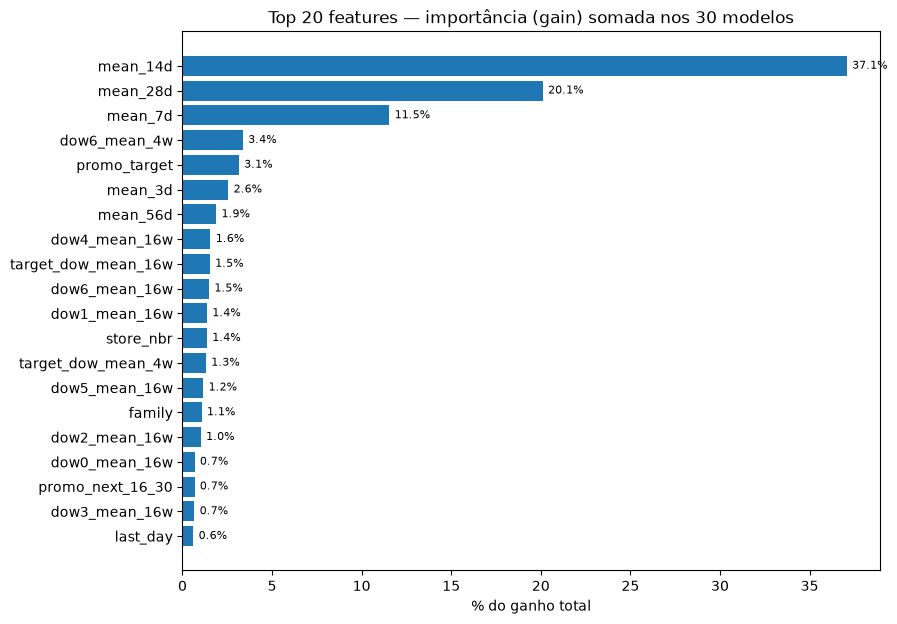

,1ª quinzena,2ª quinzena
mean_14d,41.9%,32.1%
mean_28d,13.5%,26.9%
mean_7d,16.8%,6.1%
dow6_mean_4w,3.3%,3.5%
promo_target,2.6%,3.7%
mean_3d,3.8%,1.3%
mean_56d,1.2%,2.6%
dow4_mean_16w,1.3%,1.9%
target_dow_mean_16w,1.1%,1.9%
dow6_mean_16w,1.1%,1.8%


In [8]:
imp = importance.sum(axis=1)
imp = (imp / imp.sum()).sort_values(ascending=False)

top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values * 100)
for i, v in enumerate(top.values * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set(title="Top 20 features — importância (gain) somada nos 30 modelos",
       xlabel="% do ganho total")
plt.savefig(FIG / "04_importancia_features.png", dpi=120, bbox_inches="tight")
plt.show()

# Importância por quinzena (top 10)
cols = importance.columns.astype(int)
imp_q = pd.DataFrame({
    "1ª quinzena": importance.loc[:, cols <= 15].sum(axis=1),
    "2ª quinzena": importance.loc[:, cols > 15].sum(axis=1),
})
imp_q = imp_q / imp_q.sum()
imp_q.loc[imp.head(10).index].style.format("{:.1%}")

### 💡 Insights — O que o modelo usa para prever

1. **O nível recente de vendas domina:** as médias de **14, 28 e 7 dias** somam
   **~69% da importância**. Saber "quanto este item vem vendendo nesta loja" é a
   informação mais valiosa.
2. **O modelo muda de estratégia conforme o horizonte** — confirmando a análise de
   correlação do notebook 03:
   | Feature | 1ª quinzena | 2ª quinzena |
   |---|---|---|
   | Média 7 dias | **16,8%** | 6,1% |
   | Média 14 dias | **41,9%** | 32,1% |
   | Média 28 dias | 13,5% | **26,9%** |

   Para prever mais longe, o modelo troca a "memória curta" por uma visão **mais estável**.
3. **Promoção do dia-alvo é a 5ª feature mais importante (3,1%)** e ganha peso na
   2ª quinzena (3,7%) — promoções planejadas são informação valiosa justamente
   quando o histórico recente perde força.
4. **O padrão semanal aparece em várias features** (médias por dia da semana),
   com destaque para o **domingo** (`dow6`) — o dia de maior venda.
5. **Feriado e início de mês do dia-alvo não aparecem no top 20**, o que explica os
   picos de erro em 01/ago e no feriado de 11/ago: há espaço para melhorar essas features.

## 8. Salvar as previsões de validação
A tabela com valor real e previsão de cada modelo, por loja × item × dia, alimenta a
avaliação detalhada (notebook 05) e o painel Streamlit.

In [9]:
long.to_parquet(PROC / "predictions_val.parquet", index=False)
print(f"Salvo: {len(long):,} linhas (loja × item × dia)")

Salvo: 5,025,450 linhas (loja × item × dia)
